# 3. DATA ANALYSIS & PREPROCESSING — VSL

Notebook tinh gọn phục vụ trình bày phương pháp và kết quả trong báo cáo khoa học.
**Luồng xử lý:** khảo sát dữ liệu → EDA → chất lượng → chia tập → tiền xử lý → augmentation → cân bằng lớp → DataLoader.

Chạy **Restart Kernel → Run All**. Đặt notebook cạnh thư mục `dataset/` hoặc sửa `DATA_ROOT` bên dưới.
Lần chạy đầy đủ đọc toàn bộ video train, có thể mất vài phút. Không sửa video gốc.
Biểu đồ **PNG 300 DPI/PDF** và bảng **CSV** được lưu trong `outputs_vsl_tinh_gon/`.
Notebook độc lập với notebook cũ; không đọc lại kết quả kiểm tra cũ, không huấn luyện mô hình.

**Môi trường:** Python, NumPy, pandas, OpenCV, matplotlib, PyTorch, IPython.
Nếu thiếu thư viện: `%pip install numpy pandas opencv-python matplotlib torch ipython`.
Các con số trong kết quả được tính từ dữ liệu thực, không lấy các số minh họa trong đề cương làm kết luận.

In [ ]:
# ===== CELL CẤU HÌNH: import thư viện, hằng số, hàm tiện ích =====
from pathlib import Path                      # Path: viết đường dẫn an toàn trên mọi hệ điều hành
import hashlib, pickle, re, unicodedata       # hashlib: tạo "dấu vân tay" video | pickle: đọc file mapping
                                              # re: biểu thức chính quy | unicodedata: chuẩn hóa chữ Việt
import numpy as np
import pandas as pd                           # pandas: làm việc với bảng dữ liệu (DataFrame)
import cv2                                    # OpenCV: đọc video, xử lý ảnh
import matplotlib.pyplot as plt               # vẽ biểu đồ
import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from IPython.display import display, Markdown

DATA_ROOT = Path('dataset')  # Sửa đường dẫn nếu cần.   -> thư mục chứa train/, public_test/, private_test/
OUT = Path('outputs_vsl_tinh_gon')                       # thư mục lưu biểu đồ + bảng kết quả
OUT.mkdir(exist_ok=True)                                 # tạo thư mục nếu chưa có
# SEED: cố định ngẫu nhiên để chạy lại ra cùng kết quả | T: số frame mỗi video
# SIZE: cạnh ảnh sau resize (224x224) | BATCH_SIZE: số video mỗi lượt đưa vào mô hình
SEED, T, SIZE, BATCH_SIZE = 42, 16, 224, 4
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)                                 # giới hạn số luồng CPU của PyTorch
cv2.setNumThreads(1)                                     # OpenCV dùng 1 luồng, tránh tranh chấp với PyTorch
# Mean/Std chuẩn ImageNet cho 3 kênh RGB. view(1,3,1,1) để sau này trừ/chia được cho tensor (T,3,H,W)
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
EXTENSIONS = {'.mp4', '.avi', '.mov', '.mkv', '.webm'}   # các đuôi file được coi là video
# Cấu hình font/kiểu biểu đồ (bỏ viền trên và phải cho gọn)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'pdf.fonttype': 42, 'axes.spines.top': False, 'axes.spines.right': False})

def save_table(table, name):
    # utf-8-sig: để Excel mở CSV không bị lỗi font tiếng Việt
    table.to_csv(OUT / f'{name}.csv', index=False, encoding='utf-8-sig')

def save_plot(name):
    plt.tight_layout()
    for extension in ['png', 'pdf']:                     # lưu cả PNG và PDF, độ phân giải 300 DPI
        plt.savefig(OUT / f'{name}.{extension}', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()                                          # đóng hình để giải phóng bộ nhớ

## 3.1. Dataset Overview

Mỗi video RGB biểu diễn một từ/cụm từ VSL. Nhãn train được lấy từ cấu trúc
`train/<tên lớp>/<video>`. `public_test/` và `private_test/` được giữ nguyên, không có nhãn trong notebook.

**Label processing:** dùng `label_mapping.pkl`, chuẩn hóa tên tiếng Việt về Unicode NFC,
giữ nguyên ID cho training/inference. Bảng tổng quan dưới đây là số lượng trước khi lọc chất lượng.

In [ ]:
# ===== 3.1: ĐỌC NHÃN VÀ QUÉT FILE VIDEO =====

# Đọc pickle AN TOÀN: pickle thường có thể chạy mã tùy ý khi load (nguy cơ bảo mật).
# find_class được gọi mỗi khi pickle muốn tạo class/hàm -> ta luôn báo lỗi,
# nên chỉ dữ liệu thuần (dict, str, int) mới đọc được.
class MappingReader(pickle.Unpickler):
    def find_class(self, module, name):
        raise ValueError('Mapping chỉ được chứa dữ liệu, không chứa class/hàm.')

with (DATA_ROOT / 'label_mapping.pkl').open('rb') as file:
    raw_mapping = MappingReader(file).load()             # dict: tên nhãn -> ID số
# Chuẩn hóa tên nhãn về Unicode NFC (cùng một chữ có dấu có thể mã hóa 2 cách khác nhau)
mapping = {unicodedata.normalize('NFC', k): v for k, v in raw_mapping.items()}
# Kiểm tra: (1) không có nhãn bị trùng sau chuẩn hóa, (2) ID phải là 0,1,2,...,N-1 liên tiếp
if len(mapping) != len(raw_mapping) or sorted(mapping.values()) != list(range(len(mapping))):
    raise ValueError('Cần kiểm tra tên nhãn trùng hoặc ID không liên tiếp trong mapping.')

# files: dict {tên tập -> danh sách đường dẫn video}. rglob('*') tìm đệ quy trong thư mục con,
# chỉ giữ file có đuôi video, sorted() để thứ tự luôn cố định.
files = {split: sorted(p for p in (DATA_ROOT / split).rglob('*')
                       if p.is_file() and p.suffix.lower() in EXTENSIONS)
         for split in ['train', 'public_test', 'private_test']}
overview = pd.DataFrame([{'split': s, 'videos': len(paths)} for s, paths in files.items()])  # bảng đếm video mỗi tập

# manifest: bảng liệt kê từng video train kèm nhãn
rows = []
for path in files['train']:
    parts = path.relative_to(DATA_ROOT).parts            # ví dụ ('train', 'Ăn', 'abc.mp4')
    # Nhãn = tên thư mục lớp (parts[1]); chỉ hợp lệ khi đường dẫn có đúng 3 phần
    label = unicodedata.normalize('NFC', parts[1]) if len(parts) == 3 else ''
    rows.append({'path': str(path), 'relative_path': path.relative_to(DATA_ROOT).as_posix(),
                 'label': label, 'label_id': mapping.get(label, -1)})   # -1 nếu không có trong mapping -> sẽ bị bắt ở 3.3
manifest = pd.DataFrame(rows)
label_table = pd.DataFrame(mapping.items(), columns=['label', 'label_id']).sort_values('label_id')
display(overview, label_table.head(10))
print('Số lớp trong mapping:', len(mapping))
print('Nhãn thiếu folder:', sorted(set(mapping) - set(manifest.label)))   # nhãn có trong mapping nhưng không có thư mục
save_table(overview, 'dataset_overview')
save_table(label_table, 'label_mapping')

Số lớp trong mapping: 100
Nhãn thiếu folder: []


,split,videos
0,train,3875
1,public_test,1630
2,private_test,2859


,label,label_id
0,An ủi,0
1,Áp dụng,1
2,Ăn,2
3,Ăn mừng,3
4,Ban ngày,4
5,Ban đêm,5
6,Bàn tay,6
7,Băn khoăn,7
8,Bạn thân,8
9,Bế mạc,9


## 3.2. Exploratory Data Analysis

### Phân bố lớp

Thống kê trên **train gốc**. Head: ≥50 video/lớp; Body: 20–49; Tail: <20.
Biểu đồ tỷ lệ dùng **số lớp** làm mẫu số. Số video/lớp phản ánh lượng mẫu lưu trữ,
chưa phản ánh số clip độc lập vì có thể có duplicate.

,classes,videos,class_percent,video_percent
group,,,,
Head,42,2562,42.0,66.12
Body,27,1005,27.0,25.94
Tail,31,308,31.0,7.95


,videos
count,100.000000
mean,38.750000
std,22.776638
min,6.000000
25%,15.750000
50%,45.500000
75%,59.000000
max,74.000000


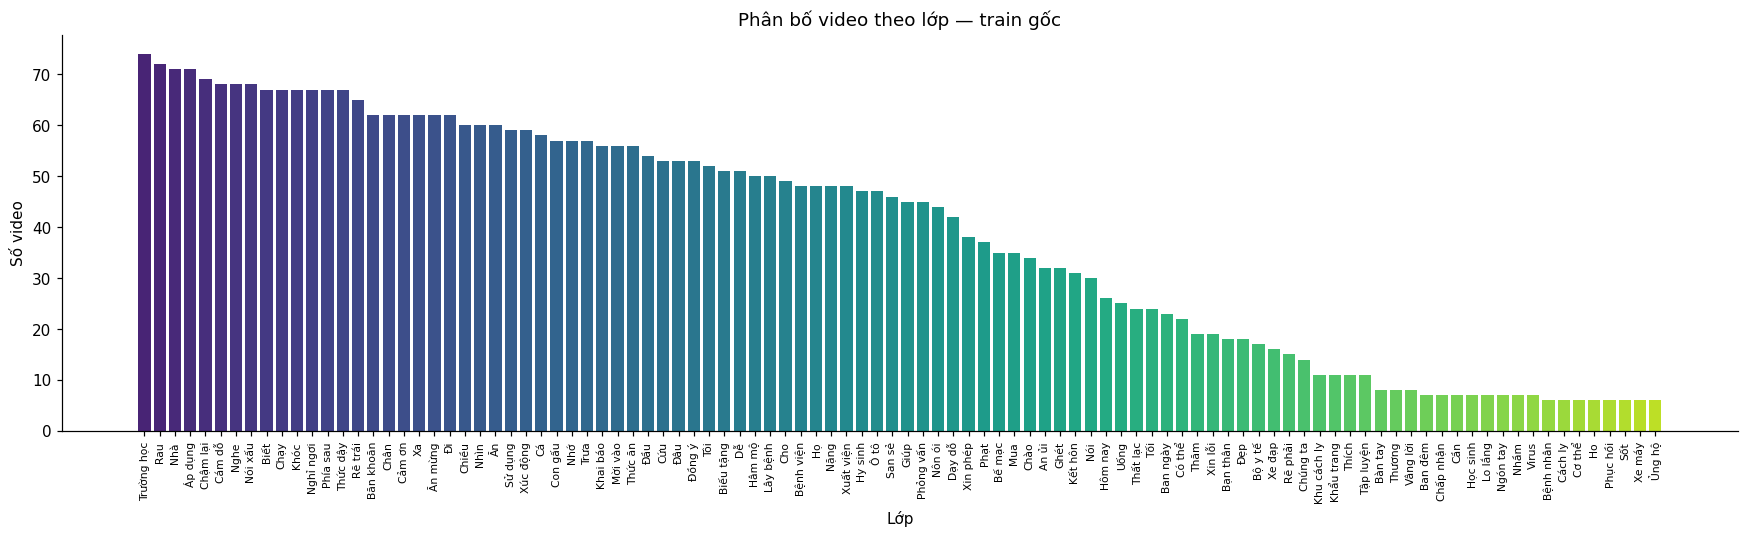

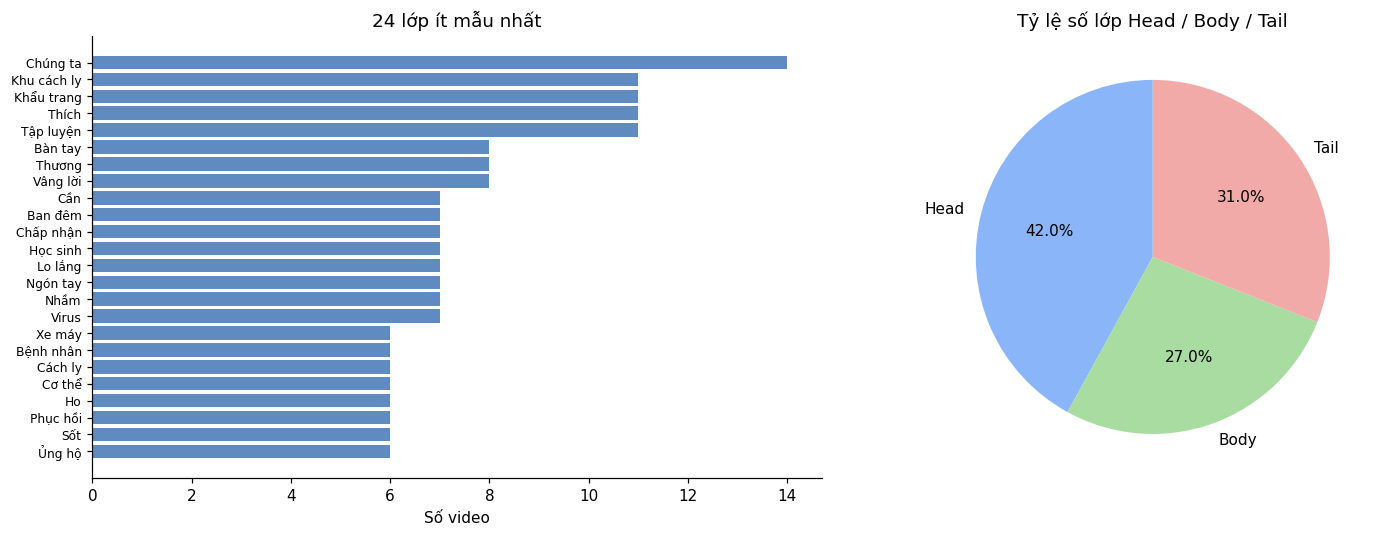

In [ ]:
# ===== 3.2 (a): PHÂN BỐ LỚP =====
# counts: số video của mỗi lớp, sắp xếp giảm dần theo số video (hòa thì theo tên)
counts = manifest.groupby('label').size().rename('videos').reset_index()
counts = counts.sort_values(['videos', 'label'], ascending=[False, True])
# np.select hoạt động như if/elif/else: >=50 -> Head, >=20 -> Body, còn lại -> Tail
counts['group'] = np.select([counts.videos.ge(50), counts.videos.ge(20)], ['Head', 'Body'], 'Tail')
# groups: mỗi nhóm có bao nhiêu lớp, bao nhiêu video
groups = counts.groupby('group').agg(classes=('label', 'size'), videos=('videos', 'sum'))
groups = groups.reindex(['Head', 'Body', 'Tail'], fill_value=0)   # sắp đúng thứ tự, nhóm thiếu thì = 0
groups['class_percent'] = 100 * groups.classes / len(counts)      # % số lớp
groups['video_percent'] = 100 * groups.videos / counts.videos.sum()  # % số video
display(groups.round(2), counts.videos.describe().to_frame())     # describe: min/max/mean/... số video mỗi lớp
save_table(counts, 'class_counts')
save_table(groups.reset_index(), 'class_groups')

# Biểu đồ 1: cột số video của từng lớp (toàn bộ 100 lớp)
fig, ax = plt.subplots(figsize=(16, 5))
ax.bar(counts.label, counts.videos, color=plt.cm.viridis(np.linspace(0.1, 0.9, len(counts))))
ax.tick_params(axis='x', rotation=90, labelsize=7)                # xoay tên lớp 90 độ cho dễ đọc
ax.set(xlabel='Lớp', ylabel='Số video', title='Phân bố video theo lớp — train gốc')
save_plot('01_class_distribution')

# Biểu đồ 2: bên trái = 24 lớp ít video nhất, bên phải = tỷ lệ số lớp Head/Body/Tail
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
rare = counts.tail(24).sort_values('videos')                      # tail(24): 24 dòng cuối = ít video nhất
axes[0].barh(rare.label, rare.videos, color='#608bc1')
axes[0].tick_params(axis='y', labelsize=8)
axes[0].set(xlabel='Số video', title='24 lớp ít mẫu nhất')
axes[1].pie(groups.classes, labels=groups.index, autopct='%1.1f%%',
            colors=['#8ab6f9', '#a8dca1', '#f1aaa8'], startangle=90)
axes[1].set_title('Tỷ lệ số lớp Head / Body / Tail')
save_plot('02_rare_classes_and_groups')

### Thông số video

Giải mã toàn bộ train để đếm frame thực đọc được, đo kích thước frame và phát hiện khung đồng màu.
FPS lấy từ metadata; thời lượng ước tính bằng **số frame đọc được / FPS**, không phải thời gian đo từ timestamp.
SHA-256 của chuỗi pixel kèm kích thước frame giúp phát hiện video có nội dung giải mã giống hệt nhau.
Mỗi lần chỉ giữ frame của một video trong RAM.

Đã đọc 500/3875 video
Đã đọc 1000/3875 video
Đã đọc 1500/3875 video
Đã đọc 2000/3875 video
Đã đọc 2500/3875 video
Đã đọc 3000/3875 video
Đã đọc 3500/3875 video
Đã đọc 3875/3875 video


,width,height,aspect_ratio,frames,fps,duration_s
count,3875.0,3875.0,3875.0,3875.000,3875.000,3875.000
mean,224.0,224.0,1.0,29.876,12.935,2.481
std,0.0,0.0,0.0,1.264,3.110,1.357
min,224.0,224.0,1.0,16.000,0.850,0.700
25%,224.0,224.0,1.0,30.000,10.976,2.133
50%,224.0,224.0,1.0,30.000,12.336,2.432
75%,224.0,224.0,1.0,30.000,14.063,2.733
max,224.0,224.0,1.0,30.000,30.018,35.294


,width,height,videos
0,224,224,3875


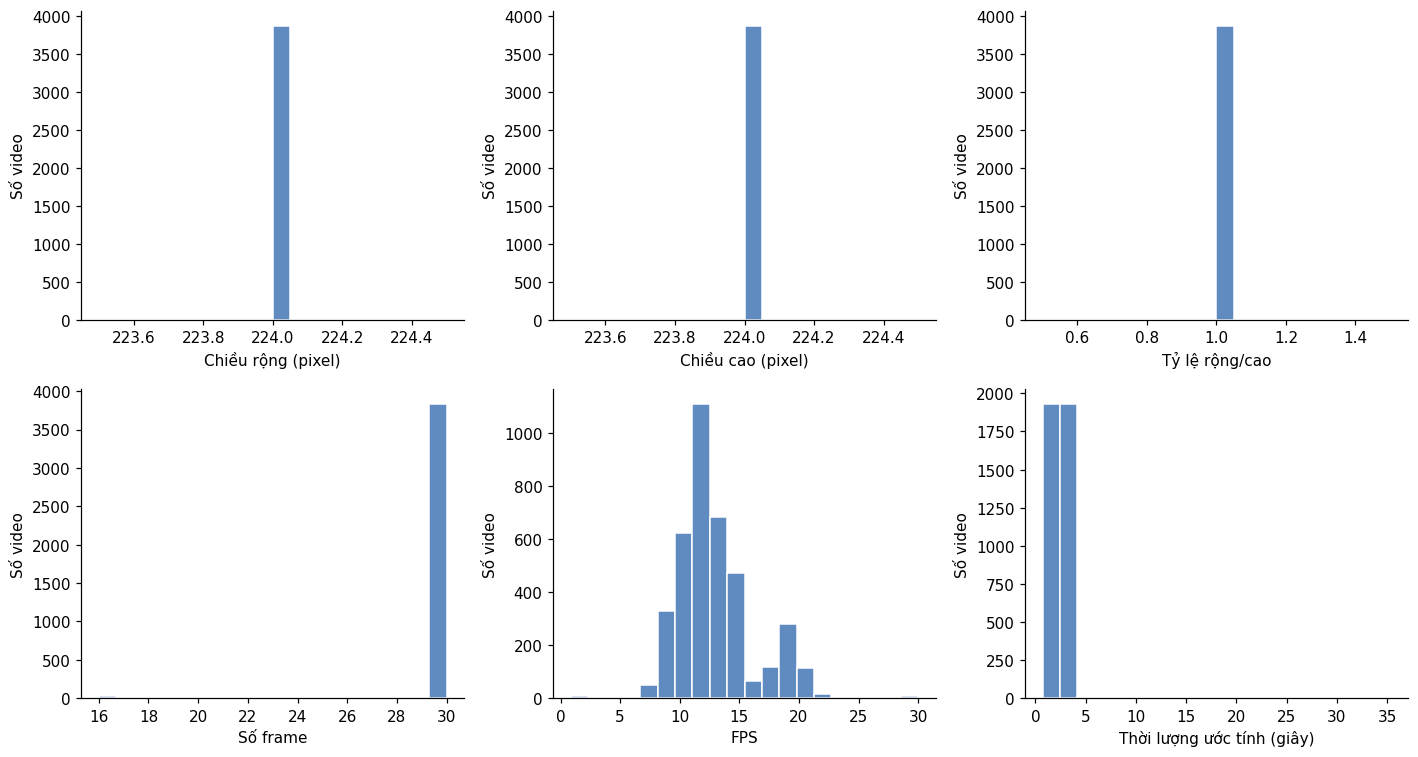

In [ ]:
# ===== 3.2 (b): ĐO THÔNG SỐ TỪNG VIDEO TRAIN =====

def read_video(path):
    """Đọc toàn bộ frame của 1 video. Trả về (danh sách frame RGB, FPS, số frame theo metadata)."""
    cap = cv2.VideoCapture(str(path))
    frames = []
    try:
        fps = cap.get(cv2.CAP_PROP_FPS)                    # FPS ghi trong metadata
        reported = cap.get(cv2.CAP_PROP_FRAME_COUNT)       # số frame ghi trong metadata (có thể sai)
        while cap.isOpened():
            ok, frame = cap.read()                         # đọc 1 frame; ok=False khi hết video / lỗi
            if not ok:
                break
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))   # OpenCV đọc BGR -> đổi sang RGB
    finally:
        cap.release()                                      # luôn đóng file, kể cả khi có lỗi
    return frames, fps, reported

records = []
for i, row in enumerate(manifest.to_dict('records'), 1):
    frames, fps, reported = read_video(row['path'])
    digest, flat_count = hashlib.sha256(), 0               # digest: "dấu vân tay"; flat_count: đếm frame đồng màu
    for frame in frames:
        # Đưa kích thước + toàn bộ pixel vào hash -> 2 video giống hệt từng pixel sẽ cùng hash
        digest.update(np.asarray(frame.shape, dtype='<i4').tobytes())
        digest.update(frame.tobytes())
        # meanStdDev(...)[1] = độ lệch chuẩn từng kênh RGB; max <= 1 nghĩa là frame gần như một màu duy nhất
        flat_count += int(cv2.meanStdDev(frame)[1].max() <= 1.0)
    h, w = frames[0].shape[:2] if frames else (0, 0)       # chiều cao, rộng lấy từ frame đầu
    records.append({**row, 'frames': len(frames), 'metadata_frames': reported,
                    'fps': fps, 'width': w, 'height': h,
                    'duration_s': len(frames) / fps if fps > 0 else np.nan,   # thời lượng ước tính = số frame / FPS
                    'aspect_ratio': w / h if h else np.nan,                   # tỷ lệ rộng/cao
                    'flat_frames': flat_count, 'hash': digest.hexdigest() if frames else '',
                    'shape_changed': any(f.shape != frames[0].shape for f in frames)})  # có frame nào đổi kích thước không
    if i % 500 == 0 or i == len(manifest):
        print(f'Đã đọc {i}/{len(manifest)} video', flush=True)   # in tiến độ mỗi 500 video
audit = pd.DataFrame(records)                              # audit: bảng thông số của mọi video train
save_table(audit, 'video_statistics')

columns = ['width', 'height', 'aspect_ratio', 'frames', 'fps', 'duration_s']
titles = ['Chiều rộng (pixel)', 'Chiều cao (pixel)', 'Tỷ lệ rộng/cao',
          'Số frame', 'FPS', 'Thời lượng ước tính (giây)']
display(audit[columns].describe().round(3))               # thống kê mô tả các cột trên
resolutions = audit.groupby(['width', 'height']).size().rename('videos').reset_index()   # đếm theo độ phân giải
display(resolutions.sort_values('videos', ascending=False))
save_table(resolutions, 'resolutions')
# 6 histogram (2 hàng x 3 cột), mỗi ô một thông số
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, column, title in zip(axes.flat, columns, titles):
    ax.hist(audit[column].dropna(), bins=20, color='#608bc1', edgecolor='white')
    ax.set(xlabel=title, ylabel='Số video')
save_plot('03_video_statistics')

### Visual inspection

Mặc định chọn một lớp đại diện mỗi nhóm Head/Body/Tail, lấy ngẫu nhiên **5 video/lớp** với seed 42,
mỗi video hiển thị 6 mốc thời gian. Đặt `VISUAL_LABELS = list(mapping)` để xem tất cả các lớp.
Quan sát vị trí người/tay, nền, trang phục, ánh sáng, góc quay và diễn biến động tác.
Montage chỉ hỗ trợ nhận xét định tính trên mẫu đã xem; cần xem video gốc để đánh giá tốc độ thực hiện.
Không suy ra danh tính người ký hay khẳng định tính đa dạng của toàn bộ dataset từ vài mẫu.

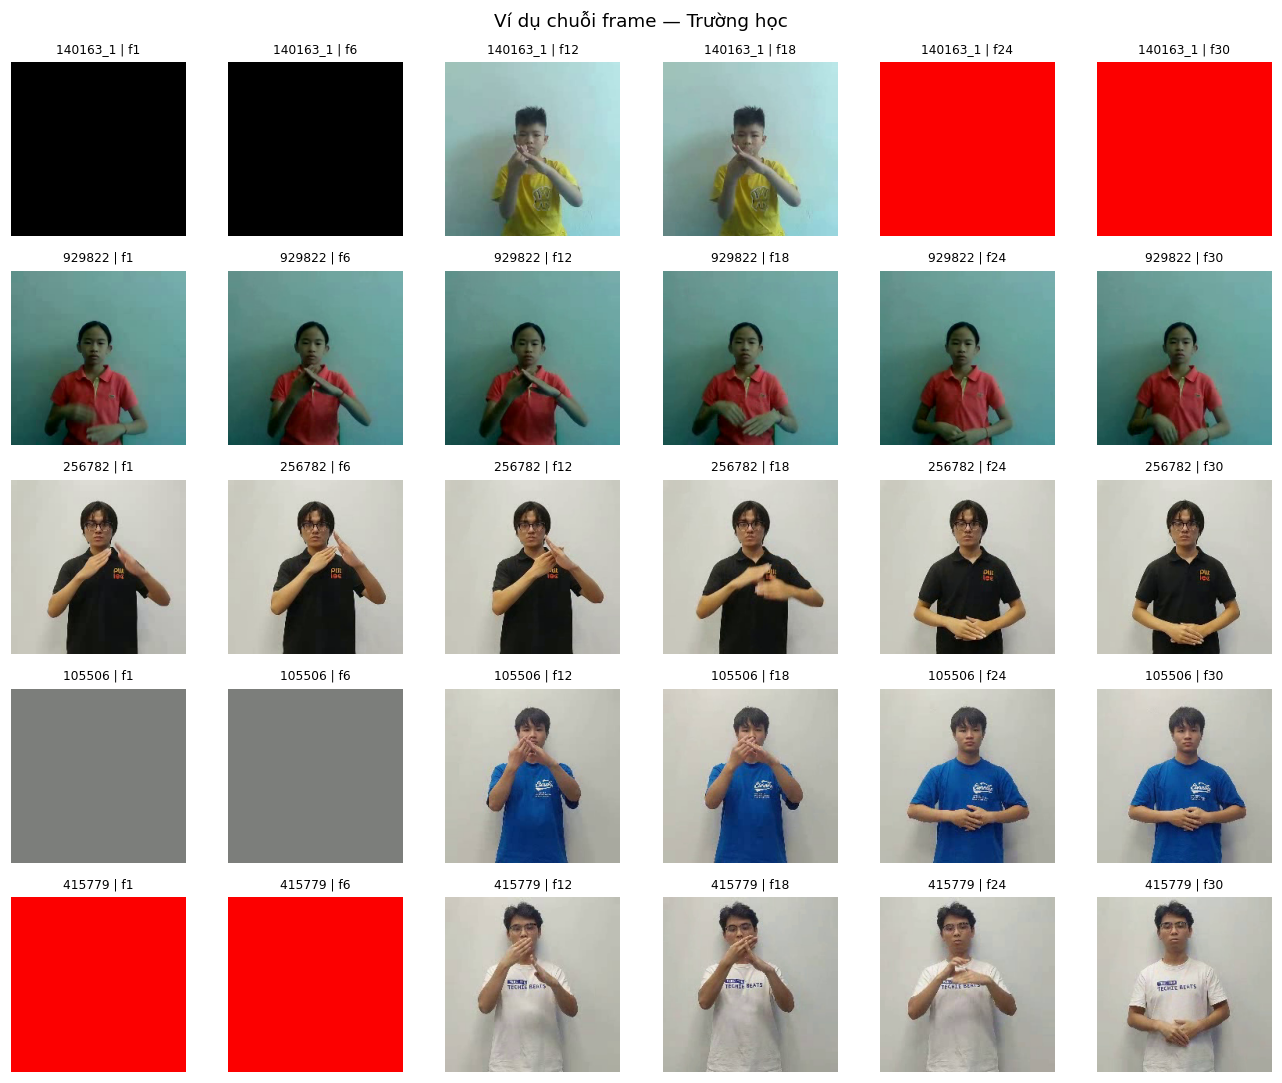

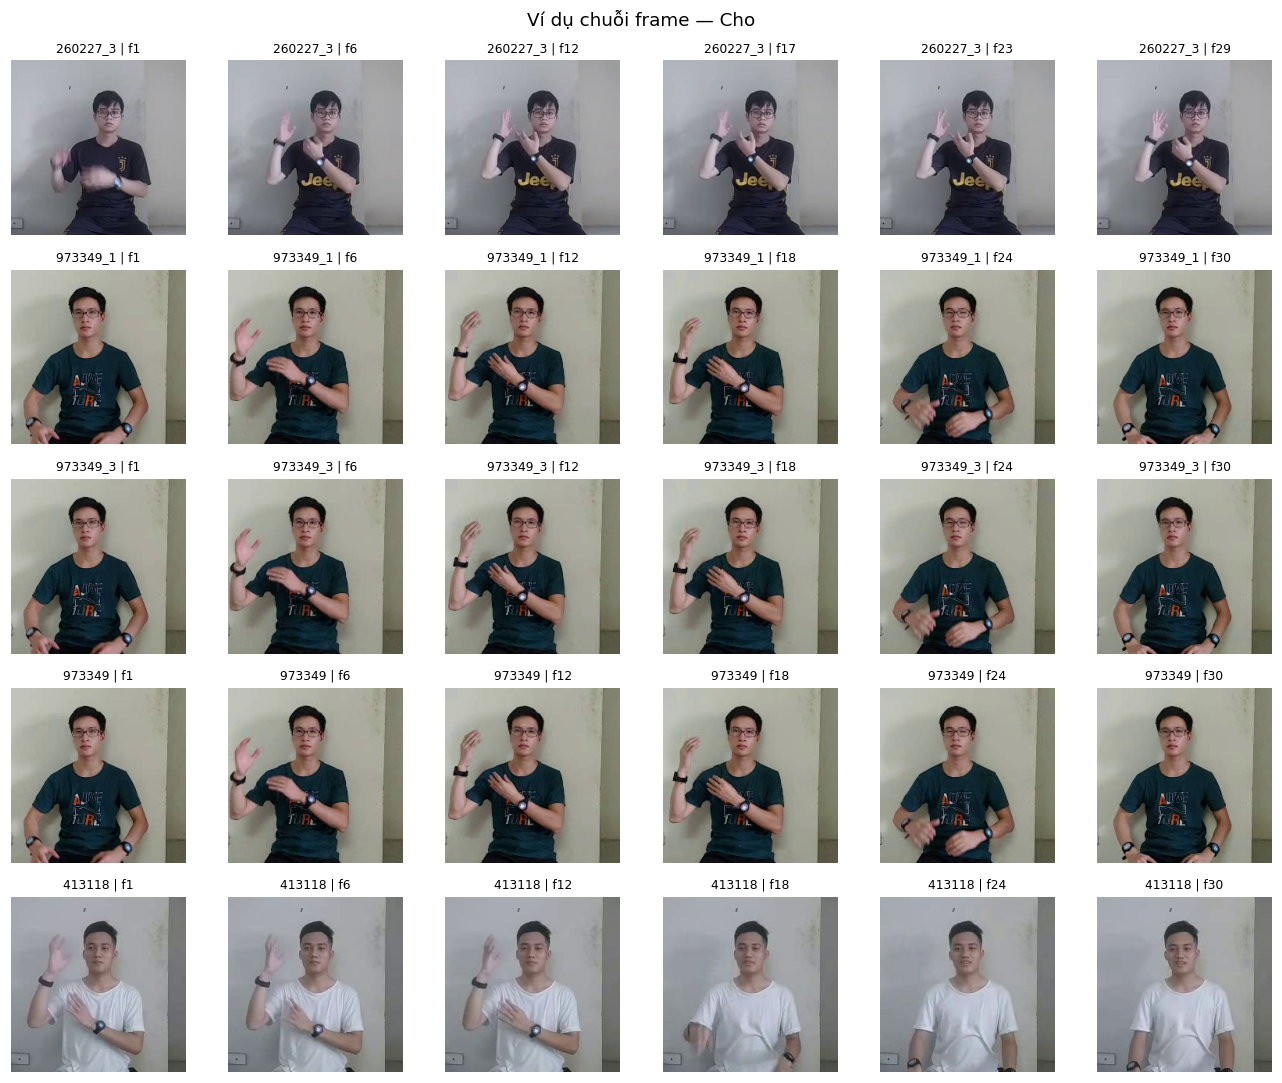

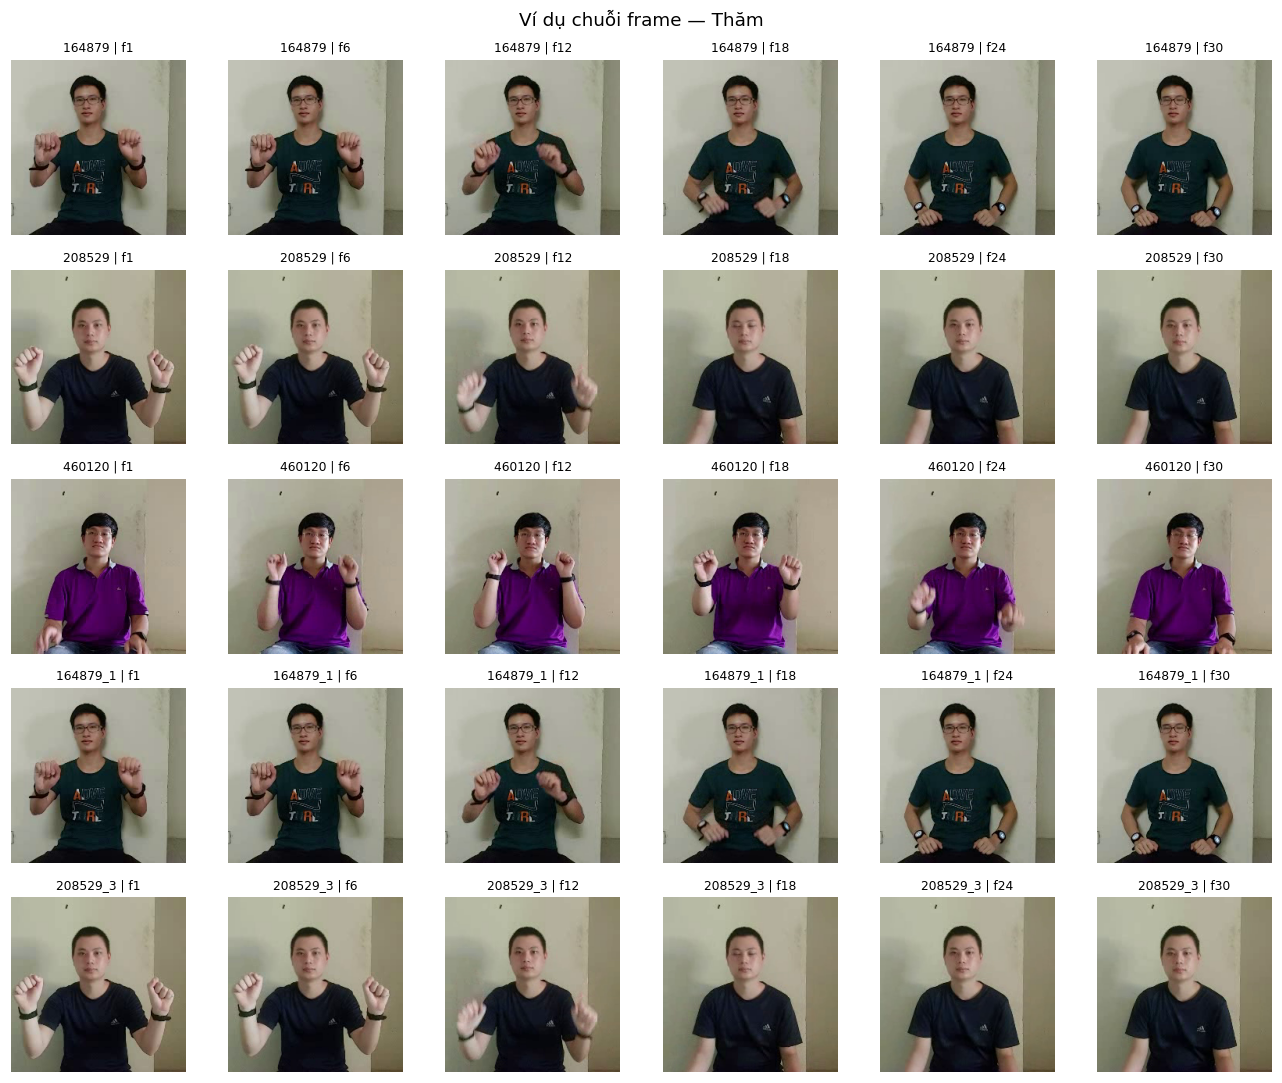

In [ ]:
# ===== 3.2 (c): XEM TRỰC QUAN VIDEO =====
# Với mỗi nhóm Head/Body/Tail lấy lớp đầu tiên (counts đã sắp giảm dần nên = lớp nhiều video nhất của nhóm)
VISUAL_LABELS = [counts.loc[counts.group.eq(g), 'label'].iloc[0]
                 for g in ['Head', 'Body', 'Tail'] if counts.group.eq(g).any()]
VIDEOS_PER_CLASS = 5                                      # số video xem mỗi lớp
visual_rows = []
for number, label in enumerate(VISUAL_LABELS, 1):
    candidates = audit[audit.label.eq(label) & audit.frames.gt(0)]       # chỉ lấy video có frame đọc được
    sample = candidates.sample(min(VIDEOS_PER_CLASS, len(candidates)), random_state=SEED)  # lấy ngẫu nhiên, cố định seed
    if sample.empty:
        continue
    visual_rows.extend(sample[['relative_path', 'label']].to_dict('records'))
    fig, axes = plt.subplots(len(sample), 6, figsize=(12, 2 * len(sample)), squeeze=False)  # mỗi video 1 hàng, 6 frame
    for row_index, row in enumerate(sample.itertuples()):
        frames, _, _ = read_video(row.path)               # đọc lại video để lấy frame hiển thị
        # linspace: 6 chỉ số frame cách đều từ đầu đến cuối video
        for ax, index in zip(axes[row_index], np.linspace(0, len(frames)-1, 6).astype(int)):
            ax.imshow(frames[index])
            ax.set_title(f'{Path(row.path).stem} | f{index+1}', fontsize=8)
            ax.axis('off')
    fig.suptitle(f'Ví dụ chuỗi frame — {label}')
    save_plot(f'04_visual_{number:03d}')
save_table(pd.DataFrame(visual_rows), 'visual_samples')   # lưu danh sách video đã xem để tái lập

## 3.3. Data Quality Analysis

Phân biệt **lỗi cần loại** và **dấu hiệu cần xem lại**:

- Loại khỏi pipeline: không đọc được frame, kích thước không hợp lệ/thay đổi, thiếu nhãn,
  toàn bộ frame đồng màu, hoặc nội dung giống hệt nhưng có nhãn khác nhau.
- Gắn cờ, vẫn giữ: FPS ngoài [1,120], ít hơn 16 frame, lệch số frame metadata/giải mã,
  hoặc chỉ một phần frame đồng màu. Ngưỡng FPS là quy ước rà soát, không chứng minh video hỏng.
- Frame đồng màu: độ lệch chuẩn không gian của từng kênh RGB ≤1 trên thang [0,255].
- Duplicate cùng nhãn được giữ, nhưng phải nằm cùng nhóm khi chia tập. Hash chưa phát hiện
  mọi trường hợp gần trùng sau crop, đổi màu hoặc mã hóa lại.

OpenCV có thể dừng đọc mà không nêu nguyên nhân; bảng này không bảo đảm phát hiện mọi lỗi codec.
Chỉ train được giải mã; chưa đánh giá chất lượng và trùng lặp train–test.

In [ ]:
# ===== 3.3: KIỂM TRA CHẤT LƯỢNG DỮ LIỆU =====
readable = audit[audit.hash.ne('')]                       # chỉ xét video đọc được (có hash)
# Gom video theo hash: videos = số video cùng hash, labels = số nhãn khác nhau trong nhóm đó
duplicates = readable.groupby('hash').agg(videos=('path', 'size'), labels=('label', 'nunique'))
duplicates = duplicates[duplicates.videos.gt(1)]          # giữ nhóm có > 1 video = nhóm trùng
conflict_hashes = duplicates.index[duplicates.labels.gt(1)]   # nhóm trùng nội dung nhưng > 1 nhãn = mâu thuẫn
# flags: bảng True/False, mỗi cột là một tiêu chí, mỗi dòng là một video
flags = pd.DataFrame({
    # ---- 4 cờ đầu: LỖI NẶNG -> loại khỏi pipeline ----
    'Không đọc được / kích thước lỗi': audit.frames.eq(0) | audit.width.le(0) | audit.height.le(0) | audit.shape_changed,
    'Không có nhãn hợp lệ': audit.label_id.lt(0),         # label_id = -1
    'Toàn bộ frame đồng màu': audit.frames.gt(0) & audit.flat_frames.eq(audit.frames),
    'Trùng nội dung, khác nhãn': audit.hash.isin(conflict_hashes),
    # ---- 4 cờ sau: chỉ CẢNH BÁO, vẫn giữ video ----
    'FPS cần xem lại': ~audit.fps.between(1, 120),        # ~ = phủ định: FPS nằm ngoài [1,120]
    'Ít hơn 16 frame': audit.frames.lt(T),
    'Số frame không khớp metadata': audit.frames.ne(audit.metadata_frames),
    'Có frame đồng màu': audit.flat_frames.gt(0),
})
quality = flags.sum().rename('videos').rename_axis('check').reset_index()   # đếm số video vi phạm mỗi tiêu chí
excluded = flags.iloc[:, :4].any(axis=1)                  # 4 cột đầu: vi phạm BẤT KỲ cột nào là bị loại
clean = audit[~excluded].copy().reset_index(drop=True)    # clean = các video còn lại (~ = lấy phần không bị loại)
display(quality)
print(f'Duplicate: {len(duplicates)} nhóm, {duplicates.videos.sum()} video (có thể chồng lặp cờ lỗi).')
print(f'Loại khỏi pipeline: {excluded.sum()}; còn lại: {len(clean)} video.')
print('Lớp có 1–2 video:', counts.loc[counts.videos.le(2), 'label'].tolist())      # lớp quá ít mẫu
print('Lớp không còn video hợp lệ:', sorted(set(mapping) - set(clean.label)))     # lớp bị mất hết video sau lọc
save_table(quality, 'quality_summary')
save_table(pd.concat([audit, flags], axis=1), 'quality_details')
save_table(audit[excluded], 'excluded_videos')
save_table(readable[readable.hash.isin(duplicates.index)], 'duplicate_videos')

Duplicate: 550 nhóm, 1649 video (có thể chồng lặp cờ lỗi).
Loại khỏi pipeline: 9; còn lại: 3866 video.
Lớp có 1–2 video: []
Lớp không còn video hợp lệ: []


,check,videos
0,Không đọc được / kích thước lỗi,0
1,Không có nhãn hợp lệ,0
2,Toàn bộ frame đồng màu,4
3,"Trùng nội dung, khác nhãn",5
4,FPS cần xem lại,5
5,Ít hơn 16 frame,0
6,Số frame không khớp metadata,0
7,Có frame đồng màu,758


## 3.4. Train / Validation / Test Split

Mục tiêu **train/validation xấp xỉ 80/20**, seed 42; public/private test giữ nguyên.
Để tránh cùng nội dung xuất hiện ở hai tập, nối nhóm khi video có cùng hash hoặc
cùng lớp và cùng tên gốc trước hậu tố `_1`, `_2`, … . Quy tắc tên chỉ là giả thuyết về clip nguồn.

Trong từng lớp, xáo trộn các nhóm rồi chọn nhóm cho validation nếu giúp số video gần 20% hơn;
giữ ít nhất một nhóm cho mỗi phía. Đây là **chia theo nhóm trong từng lớp bằng quy tắc tham lam**,
không phải chia ngẫu nhiên từng video hay tối ưu tỷ lệ tuyệt đối. Bảng phân bố lưu kèm giúp tái lập.

**Giới hạn:** chưa có signer ID được xác minh, nên phép chia này **không phải signer-independent**.
Nếu nghiên cứu yêu cầu đánh giá trên người ký chưa gặp, cần metadata người ký và thiết kế phép chia theo signer.

In [ ]:
# ===== 3.4: CHIA TRAIN / VALIDATION THEO NHÓM =====

# ---- BƯỚC 1: gom video "họ hàng" thành nhóm bằng Union-Find ----
# parent[i] = "đại diện" của video i. Ban đầu mỗi video là một nhóm riêng (tự làm đại diện).
parent = list(range(len(clean)))
def root(i):
    # Tìm đại diện của nhóm chứa video i (đi ngược lên parent cho đến khi gặp chính nó)
    while parent[i] != i:
        parent[i] = parent[parent[i]]    # nén đường đi: nhảy thẳng lên ông nội để lần tra sau nhanh hơn
        i = parent[i]
    return i

# source = tên file bỏ hậu tố _1, _2, ... (ví dụ 'an_1_2' -> 'an'). Đây là GIẢ THUYẾT: các file cắt từ cùng clip nguồn.
clean['source'] = clean.path.map(lambda p: re.sub(r'(?:_\d+)+$', '', Path(p).stem))
# Chạy 2 lần với 2 loại "khóa": (1) hash giống nhau, (2) cùng nhãn + cùng tên gốc
for keys in [clean.hash.tolist(), list(zip(clean.label, clean.source))]:
    seen = {}                                            # khóa -> video gần nhất đã gặp có khóa đó
    for i, key in enumerate(keys):
        if key in seen:
            parent[root(i)] = root(seen[key])            # đã gặp khóa này -> GỘP hai nhóm làm một
        seen[key] = i
clean['group_id'] = [root(i) for i in range(len(clean))]   # group_id = đại diện nhóm của mỗi video

# ---- BƯỚC 2: trong TỪNG LỚP, chọn các nhóm đưa vào validation ----
rng = np.random.default_rng(SEED)                        # bộ sinh ngẫu nhiên cố định seed
validation_groups = set()                                # tập các group_id được chọn cho validation
for label, rows in clean.groupby('label', sort=True):
    sizes = rows.groupby('group_id').size()              # mỗi nhóm trong lớp này có bao nhiêu video
    if len(sizes) < 2:                                   # cần >= 2 nhóm mới chia được
        raise ValueError(f'Lớp {label} có dưới 2 nhóm; cần bổ sung dữ liệu hoặc thiết kế split riêng.')
    group_ids = rng.permutation(sizes.index).tolist()    # xáo trộn thứ tự các nhóm
    chosen, total, target = [], 0, 0.2 * len(rows)       # target: số video mong muốn cho validation (20%)
    for group in group_ids:
        # Chọn nhóm này cho validation nếu: (1) vẫn chừa lại >= 1 nhóm cho train,
        # và (2) thêm nó vào làm tổng số video GẦN target hơn so với không thêm
        if len(chosen) < len(group_ids)-1 and abs(total+sizes[group]-target) < abs(total-target):
            chosen.append(group)
            total += sizes[group]
    validation_groups.update(chosen or [sizes.idxmin()])  # nếu chưa chọn được nhóm nào -> lấy nhóm nhỏ nhất

# ---- BƯỚC 3: tách bảng và kiểm tra ----
train_df = clean[~clean.group_id.isin(validation_groups)].reset_index(drop=True)   # nhóm không thuộc validation
val_df = clean[clean.group_id.isin(validation_groups)].reset_index(drop=True)      # nhóm thuộc validation
split_counts = pd.DataFrame({'train': train_df.label.value_counts(),
                             'validation': val_df.label.value_counts()}).fillna(0).astype(int)   # số video mỗi lớp ở từng tập
print(f'Train: {len(train_df)} | Validation: {len(val_df)} ({len(val_df)/len(clean):.2%})')
# Kiểm tra rò rỉ: số nhóm / số hash xuất hiện ở CẢ HAI tập. Kết quả phải bằng 0.
print('Nhóm / hash giao nhau:', len(set(train_df.group_id) & set(val_df.group_id)),
      '/', len(set(train_df.hash) & set(val_df.hash)))
display(split_counts.rename_axis('label').reset_index())
save_table(train_df, 'train_split')
save_table(val_df, 'validation_split')
save_table(split_counts.rename_axis('label').reset_index(), 'split_class_counts')

Train: 3092 | Validation: 774 (20.02%)
Nhóm / hash giao nhau: 0 / 0


,label,train,validation
0,An ủi,26,6
1,Ban ngày,18,5
2,Ban đêm,6,1
3,Biết,53,13
4,Biếu tặng,41,10
...,...,...,...
95,Đâu,42,11
96,Đầu,43,11
97,Đẹp,14,4
98,Đồng ý,42,11


## 3.5. Video Preprocessing

Đọc RGB → lấy đều **16 frame** bằng `linspace(...).astype(int)` → resize bilinear **224×224**
→ đổi pixel về [0,1] → ImageNet normalization. Video dưới 16 frame được lặp frame cuối.
Đầu ra một video có dạng **(T,C,H,W) = (16,3,224,224)**, kiểu float32.

Normalization: `(x − mean) / std`, với mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225).
Resize trực tiếp có thể đổi tỷ lệ hình nếu video không vuông; padding có thể tạo đoạn đứng hình.
Các phép biến đổi được thực hiện lúc DataLoader đọc dữ liệu, không ghi đè video gốc.

In [ ]:
def sample_indices(total, training=False, rng=None):
    if total == 0:
        raise ValueError('Video không có frame đọc được.')
    base = (np.linspace(0, total-1, T) if total >= T
            else np.r_[np.arange(total), np.full(T-total, total-1)])
    if training:
        speed = rng.uniform(0.9, 1.1)
        start = rng.uniform(0, max(0, total-1-base[-1]*speed))
        base = start + base * speed
    return np.clip(base, 0, total-1).astype(int)

def preprocess(frames, training=False, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    selected = [frames[i] for i in sample_indices(len(frames), training, rng)]
    if training:
        selected = crop_clip(selected, rng)
    resized = np.stack([cv2.resize(f, (SIZE, SIZE), interpolation=cv2.INTER_LINEAR) for f in selected])
    x = torch.from_numpy(resized).permute(0, 3, 1, 2).float() / 255.0
    if training:
        x = jitter_clip(x, rng)
    return ((x - MEAN) / STD).contiguous()

example_frames, _, _ = read_video(val_df.iloc[0].path)
example = preprocess(example_frames)
print('Chỉ số frame (từ 0):', sample_indices(len(example_frames)))
print('Tensor:', tuple(example.shape), '| dtype:', example.dtype)

Chỉ số frame (từ 0): [ 0  1  3  5  7  9 11 13 15 17 19 21 23 25 27 29]
Tensor: (16, 3, 224, 224) | dtype: torch.float32


## 3.6. Video Augmentation

Chỉ dùng cho train, với tham số được sinh **một lần cho toàn clip**:

- **Speed [0.9,1.1]:** thay đổi bước lấy mẫu theo thời gian. Tốc độ <1 lấy một khoảng ngắn hơn,
  tốc độ >1 tiến nhanh hơn và lặp frame cuối khi vượt cuối clip. Kết hợp trực tiếp với sampling
  để tránh việc resample rồi lấy đều toàn clip làm triệt tiêu hiệu ứng tốc độ.
- **Random crop:** giữ 85–100% diện tích, giữ tỷ lệ rộng/cao; cùng vị trí crop cho mọi frame.
- **Color jitter:** brightness/contrast/saturation có hệ số [0.8,1.2]. Đây là biên được chọn
  cho notebook; đề cương chưa quy định biên jitter. Tâm contrast dùng chung cho toàn clip.

Không lật ngang. Validation/test chỉ lấy mẫu, resize và normalize, không augmentation.
Ảnh dưới minh họa cùng một video trước/sau augmentation, đã hoàn tác normalization để hiển thị.

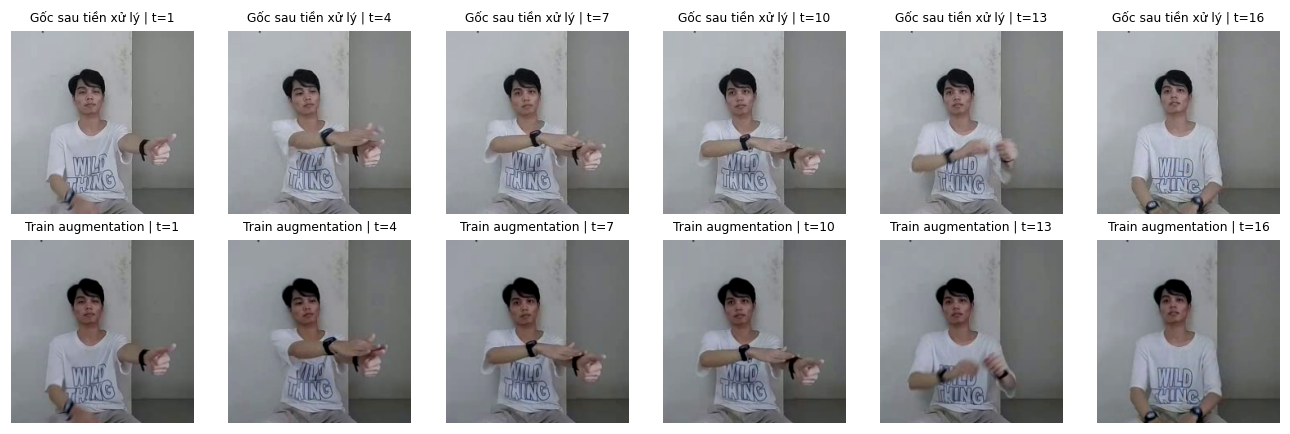

In [ ]:
def crop_clip(frames, rng):
    h, w = frames[0].shape[:2]
    scale = np.sqrt(rng.uniform(0.85, 1.0))
    ch, cw = max(1, round(h*scale)), max(1, round(w*scale))
    top, left = rng.integers(0, h-ch+1), rng.integers(0, w-cw+1)
    return [f[top:top+ch, left:left+cw] for f in frames]

def jitter_clip(x, rng):
    brightness, contrast, saturation = rng.uniform(0.8, 1.2, 3)
    x = x * float(brightness)
    weights = torch.tensor([0.2989, 0.5870, 0.1140]).view(1, 3, 1, 1)
    center = (x * weights).sum(dim=1, keepdim=True).mean()
    x = (x-center) * float(contrast) + center
    gray = (x * weights).sum(dim=1, keepdim=True)
    return (gray + float(saturation)*(x-gray)).clamp(0, 1)

augmented = preprocess(example_frames, training=True, rng=np.random.default_rng(SEED))
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for row, (title, video) in enumerate([('Gốc sau tiền xử lý', example), ('Train augmentation', augmented)]):
    visible = (video * STD + MEAN).clamp(0, 1).permute(0, 2, 3, 1).numpy()
    for ax, index in zip(axes[row], np.linspace(0, T-1, 6).astype(int)):
        ax.imshow(visible[index])
        ax.set_title(f'{title} | t={index+1}', fontsize=8)
        ax.axis('off')
save_plot('05_augmentation')

## 3.7. Class Imbalance Handling

Tính trọng số **chỉ trên train sau khi chia**: mỗi video của lớp c có trọng số `1/n_c`.
`WeightedRandomSampler` lấy mẫu có hoàn lại, mỗi epoch lấy số mẫu bằng số video train.
Vì tổng trọng số của mỗi lớp bằng nhau, các lớp có xác suất được chọn bằng nhau **theo kỳ vọng**;
số mẫu thực tế mỗi epoch vẫn dao động. Cách này không tạo video mới và không thay đổi tập validation/test.

In [ ]:
train_counts = train_df.label_id.value_counts()
weights = train_df.label_id.map(1.0 / train_counts)
sampler = WeightedRandomSampler(torch.tensor(weights.to_numpy(), dtype=torch.double),
                                num_samples=len(train_df), replacement=True,
                                generator=torch.Generator().manual_seed(SEED))
balancing = train_df[['label', 'label_id']].copy()
balancing['weight'] = weights
display(balancing.groupby('label').agg(videos=('weight', 'size'),
                                      sample_weight=('weight', 'first')).head(10))
save_table(balancing, 'sampling_weights')

,videos,sample_weight
label,,
An ủi,26,0.038462
Ban ngày,18,0.055556
Ban đêm,6,0.166667
Biết,53,0.018868
Biếu tặng,41,0.024390
Bàn tay,6,0.166667
Băn khoăn,50,0.020000
Bạn thân,14,0.071429
Bế mạc,28,0.035714


## 3.8. Final Data Pipeline

`Video → RGB → sampling/padding → crop (train) → resize → jitter (train) → normalize → batch → model`.

Train dùng sampler và augmentation. Validation/test đọc theo thứ tự cố định.
`num_workers=0` phù hợp notebook trên Windows; bộ sinh augmentation giữ seed 42.
Một batch có dạng **(B,16,3,224,224)**. Train/validation trả nhãn int64;
test không có nhãn, trả đường dẫn để ghép dự đoán với video.
Chỉ đọc thử một batch mỗi tập; chưa huấn luyện hay đánh giá mô hình.

In [ ]:
class VSLDataset(Dataset):
    def __init__(self, table, training=False):
        self.rows = table.to_dict('records')
        self.training = training
        self.rng = np.random.default_rng(SEED)

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        frames, _, _ = read_video(row['path'])
        result = {'video': preprocess(frames, self.training, self.rng), 'path': row['path']}
        if 'label_id' in row:
            result['label'] = torch.tensor(row['label_id'], dtype=torch.long)
        return result

train_loader = DataLoader(VSLDataset(train_df, True), batch_size=BATCH_SIZE, sampler=sampler, num_workers=0)
val_loader = DataLoader(VSLDataset(val_df), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loaders = {s: DataLoader(VSLDataset(pd.DataFrame({'path': [str(p) for p in files[s]]})),
                            batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
                for s in ['public_test', 'private_test']}
for name, loader in {'train': train_loader, 'validation': val_loader, **test_loaders}.items():
    batch = next(iter(loader))
    print(name, '| video:', tuple(batch['video'].shape), '| dtype:', batch['video'].dtype,
          '| label:', batch['label'].dtype if 'label' in batch else 'không có')
# Đặt lại trạng thái sau minh họa để lần train đầu không bị tiêu hao chuỗi ngẫu nhiên.
train_loader.dataset.rng = np.random.default_rng(SEED)
sampler.generator.manual_seed(SEED)

train | video: (4, 16, 3, 224, 224) | dtype: torch.float32 | label: torch.int64
validation | video: (4, 16, 3, 224, 224) | dtype: torch.float32 | label: torch.int64
public_test | video: (4, 16, 3, 224, 224) | dtype: torch.float32 | label: không có
private_test | video: (4, 16, 3, 224, 224) | dtype: torch.float32 | label: không có


### Số liệu và đoạn mô tả dùng cho báo cáo

Đoạn dưới được tạo từ kết quả chạy. Các số về EDA thuộc train gốc; số train/validation thuộc dữ liệu sau lọc.
Khi viết bài, mô tả rõ phương pháp chia theo nhóm và giới hạn chưa kiểm chứng signer,
không gọi đây là đánh giá signer-independent. Bổ sung nhận xét visual sau khi xem ảnh/video thực tế.

In [ ]:
report = f"""Tập dữ liệu gồm {len(manifest):,} video train thuộc {len(counts)} lớp,
{len(files['public_test']):,} video public test và {len(files['private_test']):,} video private test.
Số video mỗi lớp trong train dao động từ {counts.videos.min()} đến {counts.videos.max()}.
Các nhóm Head, Body và Tail lần lượt có {groups.loc['Head', 'classes']},
{groups.loc['Body', 'classes']} và {groups.loc['Tail', 'classes']} lớp.
Số frame đọc được nằm trong khoảng {audit.frames.min()}–{audit.frames.max()}.

Kiểm tra chuỗi pixel phát hiện {len(duplicates)} nhóm trùng, gồm {duplicates.videos.sum()} video.
Có {excluded.sum()} video bị loại khỏi pipeline do lỗi chất lượng hoặc nhãn theo tiêu chí mục 3.3.
Sau lọc, {len(clean)} video được chia thành {len(train_df)} video train và {len(val_df)} video
validation ({len(val_df)/len(clean):.2%}) bằng cách giữ nhóm nguồn ứng viên/trùng nội dung
trong cùng tập và phân bổ theo từng lớp, seed 42. Chưa xác minh tính độc lập theo người ký.
Các bản sao cùng nhãn được giữ chung nhóm; số file không tương đương số mẫu độc lập.

Mỗi video được chuẩn hóa về 16 frame RGB kích thước 224×224 và chuẩn hóa ImageNet.
Train dùng speed augmentation [0.9,1.1], crop giữ [0.85,1.0] diện tích và color jitter [0.8,1.2]
nhất quán theo clip. WeightedRandomSampler dùng trọng số nghịch đảo số video/lớp trên train.
Validation/test không augmentation và không cân bằng lại. Test chỉ được kiểm đếm và đọc thử
một batch; chưa khảo sát đầy đủ chất lượng hay trùng lặp train–test. Chưa huấn luyện mô hình.
"""
display(Markdown(report))
(OUT / 'mo_ta_bao_cao.md').write_text(report, encoding='utf-8')
print('Biểu đồ PNG/PDF, bảng CSV và đoạn mô tả:', OUT.resolve())

Biểu đồ PNG/PDF, bảng CSV và đoạn mô tả: C:\Users\Admin\Downloads\dataset\outputs_vsl_tinh_gon


Tập dữ liệu gồm 3,875 video train thuộc 100 lớp,
1,630 video public test và 2,859 video private test.
Số video mỗi lớp trong train dao động từ 6 đến 74.
Các nhóm Head, Body và Tail lần lượt có 42,
27 và 31 lớp.
Số frame đọc được nằm trong khoảng 16–30.

Kiểm tra chuỗi pixel phát hiện 550 nhóm trùng, gồm 1649 video.
Có 9 video bị loại khỏi pipeline do lỗi chất lượng hoặc nhãn theo tiêu chí mục 3.3.
Sau lọc, 3866 video được chia thành 3092 video train và 774 video
validation (20.02%) bằng cách giữ nhóm nguồn ứng viên/trùng nội dung
trong cùng tập và phân bổ theo từng lớp, seed 42. Chưa xác minh tính độc lập theo người ký.
Các bản sao cùng nhãn được giữ chung nhóm; số file không tương đương số mẫu độc lập.

Mỗi video được chuẩn hóa về 16 frame RGB kích thước 224×224 và chuẩn hóa ImageNet.
Train dùng speed augmentation [0.9,1.1], crop giữ [0.85,1.0] diện tích và color jitter [0.8,1.2]
nhất quán theo clip. WeightedRandomSampler dùng trọng số nghịch đảo số video/lớp trên train.
Validation/test không augmentation và không cân bằng lại. Test chỉ được kiểm đếm và đọc thử
một batch; chưa khảo sát đầy đủ chất lượng hay trùng lặp train–test. Chưa huấn luyện mô hình.
